# QR Pipeline — Cải tiến (Không dùng Real-ESRGAN)
Pipeline gọn nhẹ, tốc độ cao với các kỹ thuật tiền xử lý ảnh sắc nét, **Quiet Zone Padding 64px** và các bộ giải mã **tự động xoay đa hướng**.

### **Quy trình hoạt động:**
1. **Bước 1**: Phát hiện vị trí QR (`qrdet` / YOLOv8)
2. **Bước 2**: Warp Perspective (OpenCV) & đệm viền trắng **Quiet Zone 64px**
3. **Bước 3**: Multi-Decoder lần 1 trên ảnh Warp (`pyzbar` [tự động xoay], `zxing-cpp` [try_rotate=True], `OpenCV QRCodeDetector`, `WeChatQRCode` [tự động xoay])
4. **Fallback cải tiến** (với các QR chưa decode được):
   - Tạo 3 phiên bản ảnh:
     1. **Gốc** (Warp ban đầu)
     2. **Sharpen với Laplacian**
     3. **Unsharp Masking** (`GaussianBlur sigma=3` + `addWeighted`)
   - Đưa cả 3 phiên bản qua **Upscale 2x + Otsu Threshold + Quiet Zone Padding 64px**
   - Giải mã bằng cả 4 bộ decoder có tự động xoay đa hướng

In [8]:
import sys, os
_ROOT = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))
if _ROOT not in sys.path:
    sys.path.insert(0, _ROOT)

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def show(img, title="", cmap=None):
    plt.figure(figsize=(6, 6))
    if cmap is None and img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap or "gray")
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

# ── Cấu hình đường dẫn ───────────────────────────────────────────
IMAGE_PATH     = os.path.join(_ROOT, "adown.jpg")
# Đặt True để ép chạy bước Fallback trên TẤT CẢ các QR để quan sát
FORCE_RUN_ALL  = True
# ─────────────────────────────────────────────────────────────────
print("Config OK — FORCE_RUN_ALL:", FORCE_RUN_ALL)

Config OK — FORCE_RUN_ALL: True


## Bước 0 — Đọc ảnh gốc

Kích thước ảnh: (1280, 720, 3)


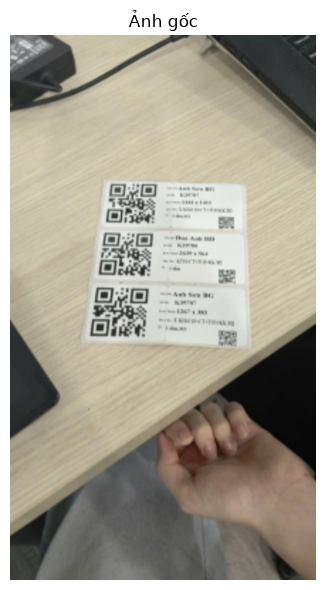

In [9]:
image_bgr = cv2.imread(IMAGE_PATH)
if image_bgr is None:
    raise FileNotFoundError(f"Không đọc được: {IMAGE_PATH}")

print(f"Kích thước ảnh: {image_bgr.shape}")
show(image_bgr, "Ảnh gốc")

## Bước 1 — Phát hiện QR (qrdet / YOLOv8)

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Số QR phát hiện: 3


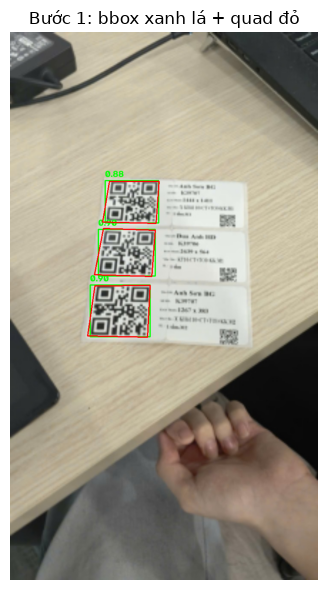

In [10]:
from production.detector import QRDetector

detector = QRDetector(model_size="s", conf_th=0.5)
detections = detector.detect(image_bgr)
print(f"Số QR phát hiện: {len(detections)}")

vis = image_bgr.copy()
for det in detections:
    x1, y1, x2, y2 = map(int, det.bbox_xyxy)
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
    pts = det.quad_xy.astype(np.int32).reshape((-1, 1, 2))
    cv2.polylines(vis, [pts], isClosed=True, color=(0, 0, 255), thickness=2)
    cv2.putText(vis, f"{det.confidence:.2f}", (x1, max(y1 - 8, 0)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

show(vis, "Bước 1: bbox xanh lá + quad đỏ")

## Bước 2 — Crop + Warp Perspective (tích hợp Quiet Zone Padding 64px)
Warp phối cảnh và đệm thêm 64px viền trắng quanh mã QR theo chuẩn ISO/IEC 18004 để đảm bảo các Finder Pattern không bị chạm mép ảnh.

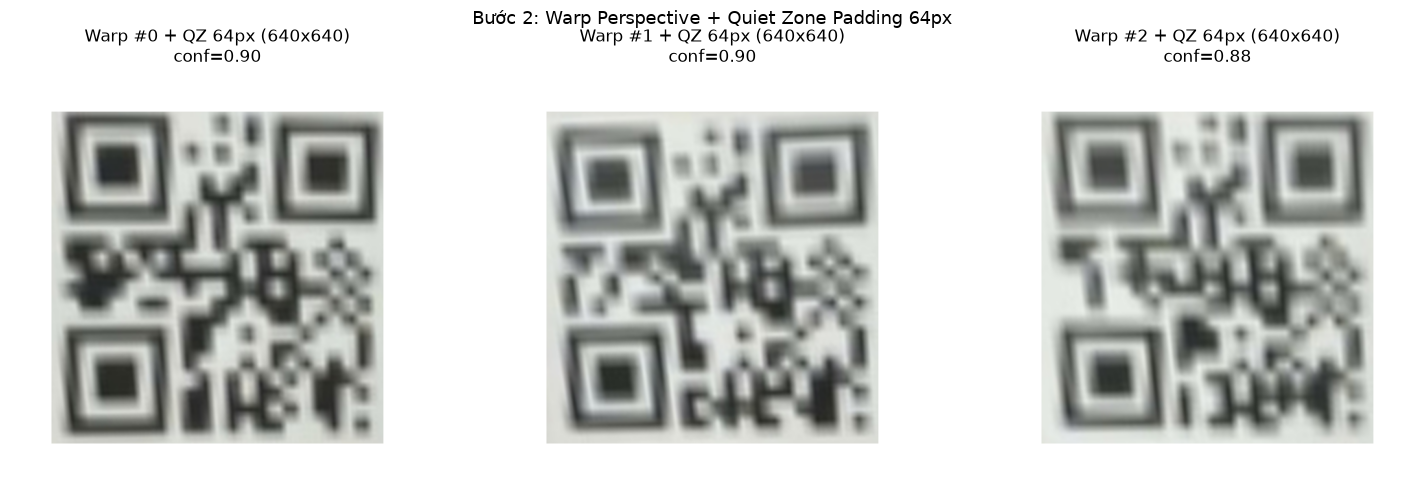

In [11]:
from production.corrector import warp_qr, add_quiet_zone

if not detections:
    print("Không có detection để warp.")
    warped_list = []
    warped_qz_list = []
else:
    # Warp chuẩn 512x512
    warped_list = [warp_qr(image_bgr, det, out_size=512) for det in detections]
    # Đệm thêm 64px viền trắng Quiet Zone (thành 640x640)
    warped_qz_list = [add_quiet_zone(w, pad_px=64) for w in warped_list]

    cols = min(len(warped_qz_list), 3)
    rows = (len(warped_qz_list) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
    axes = np.array(axes).flatten() if len(warped_qz_list) > 1 else [axes]
    for i, w in enumerate(warped_qz_list):
        axes[i].imshow(cv2.cvtColor(w, cv2.COLOR_BGR2RGB))
        axes[i].set_title(f"Warp #{i} + QZ 64px ({w.shape[1]}x{w.shape[0]})\nconf={detections[i].confidence:.2f}")
        axes[i].axis("off")
    for ax in axes[len(warped_qz_list):]:
        ax.set_visible(False)
    plt.suptitle("Bước 2: Warp Perspective + Quiet Zone Padding 64px", fontsize=13)
    plt.tight_layout()
    plt.show()

## Bước 3 — Multi-Decoder lần 1 (ảnh Warp)
Chạy 4 decoder song song có tích hợp **tự động xoay đa hướng**:
- `pyzbar` (tự động xoay 4 hướng 0°, 90°, 180°, 270°)
- `zxing-cpp` (`try_rotate=True`, `try_downscale=True`)
- `cv2.QRCodeDetector`
- `WeChatQRCode` (tự động xoay đa hướng)

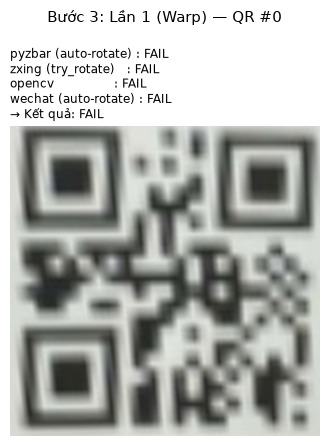

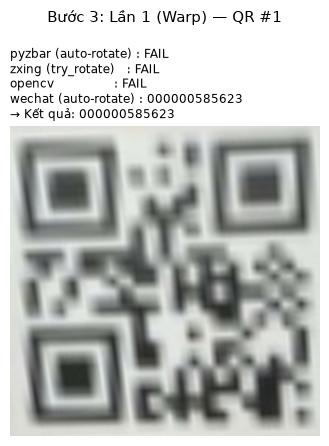

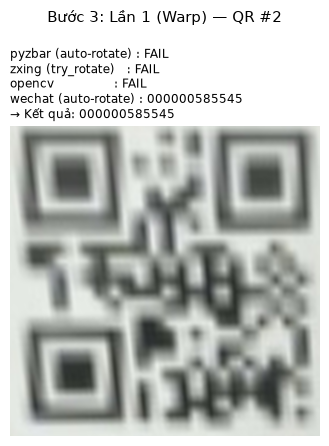

Lần 1 thành công: 2/3
QR sẽ chạy tiếp sang Fallback cải tiến: [0, 1, 2]


In [12]:
from production.decoder import _decode_pyzbar, _decode_zxing, _decode_opencv, _decode_wechat

def decode_all_methods(img):
    """Chạy 4 bộ decoder trên 1 ảnh và trả về kết quả từng bộ (đã bật tự động xoay)."""
    r_pyzbar = _decode_pyzbar(img)
    r_zxing  = _decode_zxing(img)
    r_opencv = _decode_opencv(img)
    r_wechat = _decode_wechat(img)
    best = r_pyzbar or r_zxing or r_opencv or r_wechat
    return {
        "pyzbar": r_pyzbar,
        "zxing": r_zxing,
        "opencv": r_opencv,
        "wechat": r_wechat,
        "result": best,
    }

decode1_results = []
for i, w in enumerate(warped_list):
    # Thử trên ảnh warp gốc
    res = decode_all_methods(w)
    # Nếu chưa ra, thử trên ảnh có Quiet Zone 64px
    if not res["result"] and i < len(warped_qz_list):
        res_qz = decode_all_methods(warped_qz_list[i])
        if res_qz["result"]:
            res = res_qz

    decode1_results.append(res["result"])

    label = (
        f"pyzbar (auto-rotate) : {res['pyzbar'] or 'FAIL'}\n"
        f"zxing (try_rotate)   : {res['zxing']  or 'FAIL'}\n"
        f"opencv               : {res['opencv'] or 'FAIL'}\n"
        f"wechat (auto-rotate) : {res['wechat'] or 'FAIL'}\n"
        f"→ Kết quả: {res['result'] or 'FAIL'}"
    )
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    ax.imshow(cv2.cvtColor(w, cv2.COLOR_BGR2RGB))
    ax.set_title(label, fontsize=8.5, loc="left")
    ax.axis("off")
    plt.suptitle(f"Bước 3: Lần 1 (Warp) — QR #{i}", fontsize=11)
    plt.tight_layout()
    plt.show()

failed_idx_1 = [i for i, r in enumerate(decode1_results) if not r]
targets_fallback = list(range(len(warped_list))) if FORCE_RUN_ALL else failed_idx_1
print(f"Lần 1 thành công: {sum(bool(r) for r in decode1_results)}/{len(decode1_results)}")
print(f"QR sẽ chạy tiếp sang Fallback cải tiến: {targets_fallback}")

## Fallback Cải Tiến — Tạo 3 biến thể (Gốc, Laplacian, Unsharp) rồi Upscale 2x + Otsu + Quiet Zone Padding 64px
Với mỗi QR cần fallback:
1. **Biến thể 1 (Gốc)**: Ảnh warp ban đầu
2. **Biến thể 2 (Laplacian Sharpen)**: Làm nét biên cạnh bằng kernel Laplacian
3. **Biến thể 3 (Unsharp Masking)**: `GaussianBlur (0, 0), sigma=3` rồi kết hợp `addWeighted(1.5, -0.5)`

Cả 3 biến thể sau đó được đưa qua **Upscale 2x + Otsu Threshold** và **đệm thêm viền trắng Quiet Zone 64px**, sau đó giải mã bằng 4 decoder có tự động xoay.

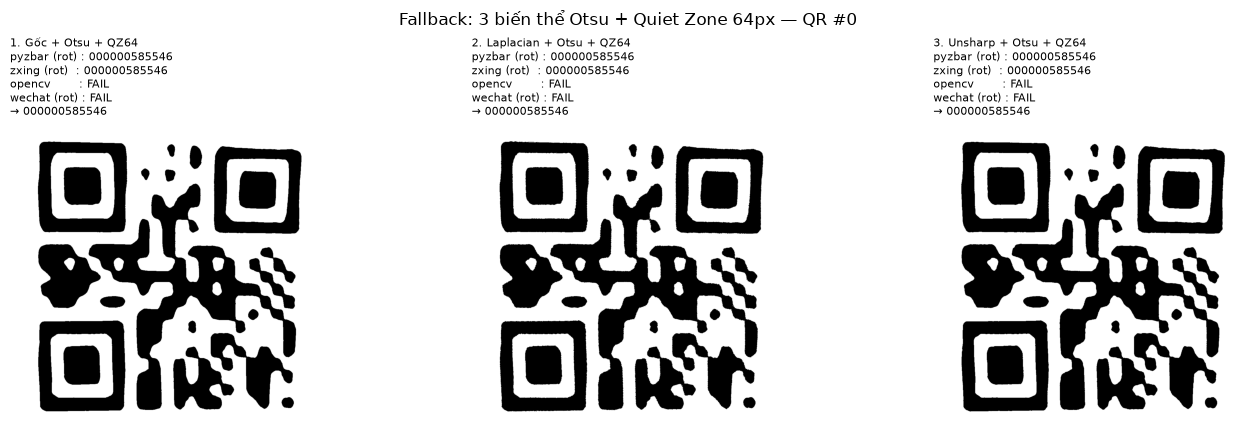

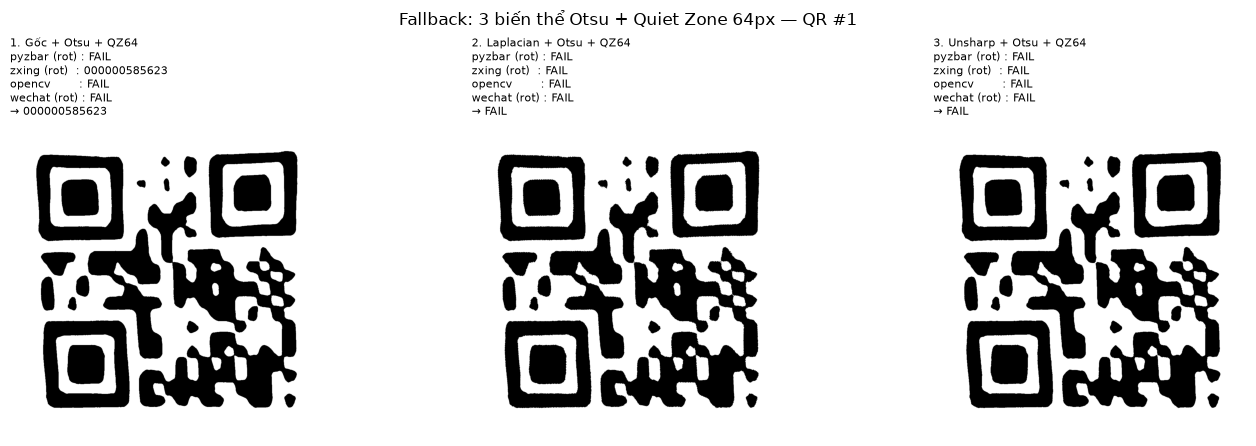

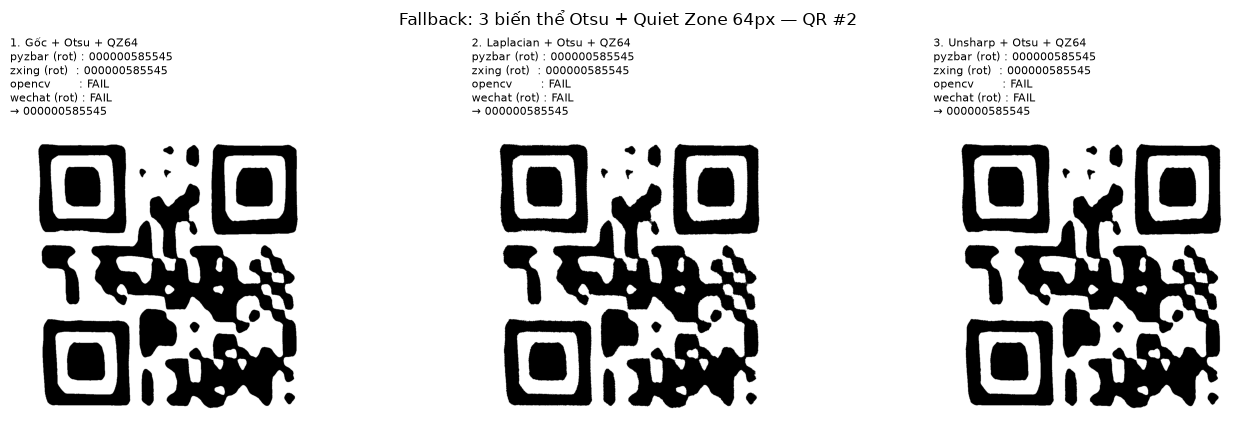

Hoàn tất kiểm thử Fallback cải tiến.


In [13]:
from production.preprocessor import sharpen_laplacian, unsharp_masking, upscale_otsu

fallback_detailed_results = {}  # {qr_idx: {variant_name: decode_dict}}
fallback_final_results    = {}  # {qr_idx: best_text}

for i in targets_fallback:
    w_img = warped_list[i]

    # 1. Tạo 3 phiên bản làm nét
    img_original = w_img.copy()
    img_lap      = sharpen_laplacian(w_img)
    img_unsharp  = unsharp_masking(w_img)

    # 2. Đưa từng phiên bản qua Upscale 2x + Otsu Threshold + Quiet Zone 64px
    otsu_original = upscale_otsu(img_original, scale=2.0, pad_px=64)
    otsu_lap      = upscale_otsu(img_lap, scale=2.0, pad_px=64)
    otsu_unsharp  = upscale_otsu(img_unsharp, scale=2.0, pad_px=64)

    variants = {
        "1. Gốc + Otsu + QZ64": otsu_original,
        "2. Laplacian + Otsu + QZ64": otsu_lap,
        "3. Unsharp + Otsu + QZ64": otsu_unsharp,
    }

    # 3. Hiển thị hình ảnh 3 biến thể Otsu có Quiet Zone 64px
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
    var_results = {}
    best_for_qr = None

    for ax_idx, (v_name, v_img) in enumerate(variants.items()):
        res = decode_all_methods(v_img)
        var_results[v_name] = res
        if res["result"] and best_for_qr is None:
            best_for_qr = res["result"]

        axes[ax_idx].imshow(cv2.cvtColor(v_img, cv2.COLOR_BGR2RGB))
        info = (
            f"{v_name}\n"
            f"pyzbar (rot) : {res['pyzbar'] or 'FAIL'}\n"
            f"zxing (rot)  : {res['zxing']  or 'FAIL'}\n"
            f"opencv       : {res['opencv'] or 'FAIL'}\n"
            f"wechat (rot) : {res['wechat'] or 'FAIL'}\n"
            f"→ {res['result'] or 'FAIL'}"
        )
        axes[ax_idx].set_title(info, fontsize=8, loc="left")
        axes[ax_idx].axis("off")

    plt.suptitle(f"Fallback: 3 biến thể Otsu + Quiet Zone 64px — QR #{i}", fontsize=12)
    plt.tight_layout()
    plt.show()

    fallback_detailed_results[i] = var_results
    fallback_final_results[i]    = best_for_qr

print("Hoàn tất kiểm thử Fallback cải tiến.")

## Tổng kết & Bảng so sánh kết quả chi tiết

QR    Lần 1 (Warp)       Gốc+Otsu+QZ64        Laplacian+Otsu       Unsharp+Otsu         KẾT QUẢ        
#0    FAIL               000000585546         000000585546         000000585546         000000585546   
#1    000000585623       000000585623         -                    -                    000000585623   
#2    000000585545       000000585545         000000585545         000000585545         000000585545   


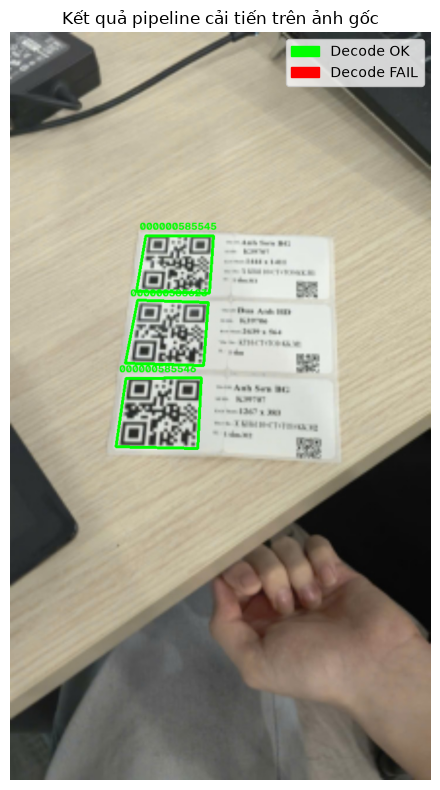

In [14]:
print("=" * 105)
print(f"{'QR':<5} {'Lần 1 (Warp)':<18} {'Gốc+Otsu+QZ64':<20} {'Laplacian+Otsu':<20} {'Unsharp+Otsu':<20} {'KẾT QUẢ':<15}")
print("=" * 105)

final = {}
for i in range(len(warped_list)):
    r1 = decode1_results[i]
    v_dict = fallback_detailed_results.get(i, {})
    r_orig    = v_dict.get("1. Gốc + Otsu + QZ64", {}).get("result")
    r_lap     = v_dict.get("2. Laplacian + Otsu + QZ64", {}).get("result")
    r_unsharp = v_dict.get("3. Unsharp + Otsu + QZ64", {}).get("result")
    
    # Ưu tiên: Lần 1 -> Gốc+Otsu -> Laplacian+Otsu -> Unsharp+Otsu
    winner = r1 or r_orig or r_lap or r_unsharp
    final[i] = winner

    s_r1      = (r1 or "FAIL")[:16]
    s_orig    = (r_orig or "-")[:18]
    s_lap     = (r_lap or "-")[:18]
    s_unsharp = (r_unsharp or "-")[:18]
    s_win     = (winner or "FAIL")[:14]

    print(f"#{i:<4} {s_r1:<18} {s_orig:<20} {s_lap:<20} {s_unsharp:<20} {s_win:<15}")
print("=" * 105)

# Vẽ kết quả lên ảnh gốc
vis_final = image_bgr.copy()
for i, det in enumerate(detections):
    pts = det.quad_xy.astype(np.int32).reshape((-1, 1, 2))
    color = (0, 255, 0) if final.get(i) else (0, 0, 255)
    cv2.polylines(vis_final, [pts], isClosed=True, color=color, thickness=3)
    x1, y1 = int(det.bbox_xyxy[0]), int(det.bbox_xyxy[1])
    label = (final.get(i) or "FAIL")[:25]
    cv2.putText(vis_final, label, (x1, max(y1 - 8, 0)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

ok_patch   = mpatches.Patch(color="lime", label="Decode OK")
fail_patch = mpatches.Patch(color="red",  label="Decode FAIL")

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(vis_final, cv2.COLOR_BGR2RGB))
plt.title("Kết quả pipeline cải tiến trên ảnh gốc")
plt.legend(handles=[ok_patch, fail_patch], loc="upper right")
plt.axis("off")
plt.tight_layout()
plt.show()